# Predicción del Riesgo de Lesión Deportiva
### Proyecto de Simulación — Aprendizaje Supervisado con Red Neuronal

**Integrantes:**
- Andres Ramos Alvarez
- Roberto Hernandez Morelo
- Angel Rodriguez Mejía

**Objetivo:** construir un modelo de aprendizaje supervisado (red neuronal) que, a partir de variables físicas y de entrenamiento de un deportista, prediga la probabilidad/clase de riesgo de lesión (`Likelihood_of_Injury`: 0 = no lesión, 1 = lesión).

**Tipo de problema:** clasificación binaria.

**Dataset:** *Injury Prediction Dataset* de Kaggle (autor: mrsimple07), archivo original **`injury_data.csv`**. Reúne datos de demografía del deportista, intensidad de entrenamiento, historial de lesiones previas y tiempos de recuperación.

> Fuente: https://www.kaggle.com/datasets/mrsimple07/injury-prediction-dataset

**Estructura del notebook**
1. Carga del dataset
2. Calidad del dataset
3. Preprocesamiento y EDA
4. Diseño preliminar de la red neuronal
5. Entrenamiento del modelo
6. Evaluación y valoración del modelo
7. Conclusiones


In [37]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn scipy tensorflow graphviz pydot


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Carga del dataset

In [38]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, classification_report)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)

print("TensorFlow:", tf.__version__)


TensorFlow: 2.21.0


In [39]:
from pathlib import Path

candidates = [
    Path("injury_data.csv"),
    Path.cwd() / "injury_data.csv",
    Path("files") / "injury_data.csv",
    Path.cwd() / "files" / "injury_data.csv",
]
DATA_PATH = next((str(p) for p in candidates if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "No se encontró 'injury_data.csv'. Debe estar en la carpeta del notebook o en la subcarpeta 'files'.")

df = pd.read_csv(DATA_PATH)
FEATURES = ["Player_Age", "Player_Weight", "Player_Height",
            "Previous_Injuries", "Training_Intensity", "Recovery_Time"]
TARGET = "Likelihood_of_Injury"
assert list(df.columns) == FEATURES + [TARGET], "El CSV no tiene las columnas esperadas"
print(f"Dataset cargado desde: {DATA_PATH}")
df.head()

Dataset cargado desde: injury_data.csv


,Player_Age,Player_Weight,Player_Height,Previous_Injuries,Training_Intensity,Recovery_Time,Likelihood_of_Injury
0,24,66.251933,175.732429,1,0.457929,5,0
1,37,70.996271,174.581650,0,0.226522,6,1
2,32,80.093781,186.329618,0,0.613970,2,1
3,28,87.473271,175.504240,1,0.252858,4,1
4,25,84.659220,190.175012,0,0.577632,1,1


## 2. Calidad del dataset 

Aquí se documenta el estado del dataset **tal como se descargó de Kaggle** (sin ningún tratamiento previo): dimensiones, tipos, nulos, duplicados, rangos válidos, valores atípicos, balance de clases y, sobre todo, **qué tanta información predictiva contiene cada variable** sobre la etiqueta.

In [40]:
print("Dimensiones (filas, columnas):", df.shape)
print("Registros por variable predictora:", len(df), "filas /", len(FEATURES), "variables")
print()

perfil = pd.DataFrame({
    "tipo":     df.dtypes.astype(str),
    "nulos":    df.isnull().sum(),
    "% nulos":  (df.isnull().mean() * 100).round(2),
    "únicos":   df.nunique(),
    "mín":      df.min().round(2),
    "máx":      df.max().round(2),
})
display(perfil)
print("Filas duplicadas:", df.duplicated().sum())

Dimensiones (filas, columnas): (1000, 7)
Registros por variable predictora: 1000 filas / 6 variables



,tipo,nulos,% nulos,únicos,mín,máx
Player_Age,int64,0,0.0,22,18.00,39.00
Player_Weight,float64,0,0.0,1000,40.19,104.65
Player_Height,float64,0,0.0,1000,145.29,207.31
Previous_Injuries,int64,0,0.0,2,0.00,1.00
Training_Intensity,float64,0,0.0,1000,0.00,1.00
Recovery_Time,int64,0,0.0,6,1.00,6.00
Likelihood_of_Injury,int64,0,0.0,2,0.00,1.00


Filas duplicadas: 0


In [41]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Player_Age,1000.0,28.231,6.538,18.000,22.000,28.000,34.000,39.000
Player_Weight,1000.0,74.794,9.893,40.192,67.944,75.021,81.303,104.650
Player_Height,1000.0,179.751,9.889,145.286,173.037,180.034,186.558,207.309
Previous_Injuries,1000.0,0.515,0.500,0.000,0.000,1.000,1.000,1.000
Training_Intensity,1000.0,0.491,0.286,0.000,0.241,0.484,0.730,0.998
Recovery_Time,1000.0,3.466,1.701,1.000,2.000,4.000,5.000,6.000
Likelihood_of_Injury,1000.0,0.500,0.500,0.000,0.000,0.500,1.000,1.000


### 2.1 Validez de los rangos (reglas de plausibilidad)

Se verifica que ningún registro viole límites físicos/lógicos razonables para deportistas.

In [42]:
reglas = {
    "Player_Age":         lambda s: s.between(14, 50),
    "Player_Weight":      lambda s: s.between(40, 150),      # kg
    "Player_Height":      lambda s: s.between(140, 220),     # cm
    "Previous_Injuries":  lambda s: s.isin([0, 1]),          # en este dataset es binaria (0/1)
    "Training_Intensity": lambda s: s.between(0, 1),         # escala normalizada 0-1
    "Recovery_Time":      lambda s: s >= 0,
    "Likelihood_of_Injury": lambda s: s.isin([0, 1]),
}
res = pd.Series({c: int((~f(df[c])).sum()) for c, f in reglas.items()}, name="registros fuera de regla")
display(res.to_frame())

# Valores atípicos estadísticos (criterio IQR 1.5x): no se eliminan, solo se reportan.
q1, q3 = df[FEATURES].quantile(.25), df[FEATURES].quantile(.75)
iqr = q3 - q1
atipicos = ((df[FEATURES] < q1 - 1.5*iqr) | (df[FEATURES] > q3 + 1.5*iqr)).sum()
print("Valores atípicos por IQR (solo informativo):")
print(atipicos.to_string())

,registros fuera de regla
Player_Age,0
Player_Weight,0
Player_Height,0
Previous_Injuries,0
Training_Intensity,0
Recovery_Time,0
Likelihood_of_Injury,0


Valores atípicos por IQR (solo informativo):
Player_Age            0
Player_Weight         7
Player_Height         5
Previous_Injuries     0
Training_Intensity    0
Recovery_Time         0


### 2.2 Balance de clases

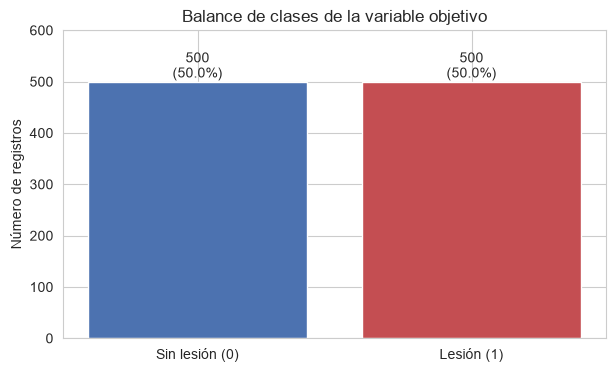

In [43]:
fig, ax = plt.subplots()
counts = df[TARGET].value_counts().sort_index()
ax.bar(["Sin lesión (0)", "Lesión (1)"], counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, f"{v}\n({v/len(df)*100:.1f}%)", ha="center")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Balance de clases de la variable objetivo")
ax.set_ylabel("Número de registros")
plt.show()

### 2.3 ¿Cuánta información predictiva tiene cada variable?

Es el punto más importante de la calidad de un dataset para aprendizaje supervisado: **no basta con que esté limpio, las variables deben estar relacionadas con la etiqueta**. Para cada variable se calcula:

- **r**: correlación punto-biserial con la etiqueta y su **p-valor** (H0: no hay relación).
- **AUC univariado**: qué tan bien separaría las clases usando *solo* esa variable (0.5 = azar).

,r,p-valor,AUC univariado,¿significativa (p<0.05)?
variable,,,,
Player_Age,0.000,0.996,0.499,No
Player_Weight,0.002,0.954,0.505,No
Player_Height,0.030,0.349,0.516,No
Previous_Injuries,0.038,0.230,0.519,No
Training_Intensity,0.089,0.005,0.552,Sí
Recovery_Time,-0.015,0.629,0.491,No


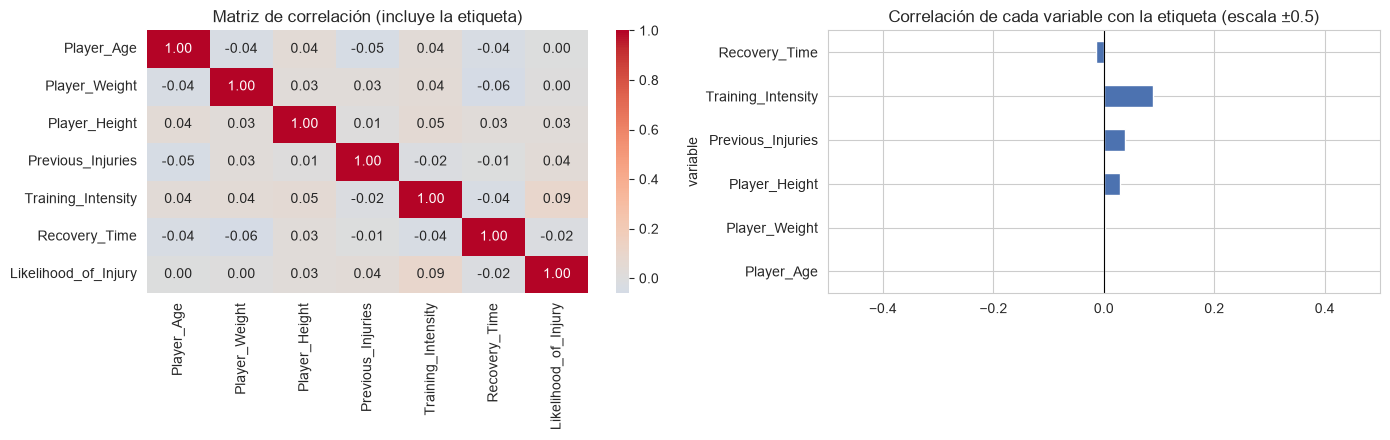

Máxima |correlación| entre predictoras: 0.061  (no hay multicolinealidad)


In [44]:
filas = []
for c in FEATURES:
    r, p = stats.pointbiserialr(df[TARGET], df[c])
    filas.append({"variable": c, "r": r, "p-valor": p,
                  "AUC univariado": roc_auc_score(df[TARGET], df[c]),
                  "¿significativa (p<0.05)?": "Sí" if p < 0.05 else "No"})
relacion = pd.DataFrame(filas).set_index("variable").round(3)
display(relacion)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Matriz de correlación (incluye la etiqueta)")
relacion["r"].plot.barh(ax=axes[1], color="#4C72B0")
axes[1].axvline(0, color="k", lw=.8)
axes[1].set_xlim(-0.5, 0.5)
axes[1].set_title("Correlación de cada variable con la etiqueta (escala ±0.5)")
plt.tight_layout(); plt.show()

print(f"Máxima |correlación| entre predictoras: "
      f"{df[FEATURES].corr().abs().where(~np.eye(len(FEATURES), dtype=bool)).max().max():.3f}  (no hay multicolinealidad)")

### 2.4 Valoración de la calidad del dataset

| Aspecto | Resultado | Valoración |
|---|---|---|
| Tamaño | 1000 registros × 6 variables | Pequeño pero suficiente para una red compacta |
| Nulos | 0 | Excelente |
| Duplicados | 0 | Excelente |
| Tipos de dato | Coherentes (numéricos) | Excelente |
| Rangos físicos | Sin violaciones | Excelente |
| Valores atípicos | Muy pocos (peso y estatura, plausibles) | Aceptable, se conservan |
| Balance de clases | 50% / 50% exacto | Ideal: no requiere sobre/submuestreo |
| Multicolinealidad | Prácticamente nula entre predictoras | Buena |
| **Poder predictivo de las variables** | **Muy bajo**: solo `Training_Intensity` se relaciona significativamente con la etiqueta (r ≈ 0.09, AUC ≈ 0.55); las demás son indistinguibles del azar | **Limitación principal** |

**Conclusión de calidad:** el dataset es *técnicamente impecable* (limpio, balanceado, sin duplicados), pero las variables tienen poca señal predictiva respecto a la etiqueta. Esto **no es un error del código**: fija el techo de desempeño alcanzable y se debe tener en cuenta al interpretar los resultados de la Sección 6.

## 3. Preprocesamiento y análisis exploratorio (EDA)

In [45]:
# Limpieza defensiva: en este dataset no hay nada que corregir, pero el código
# queda listo por si se usa una versión con problemas.
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicados eliminados:", antes - len(df))

n_nulos = int(df[FEATURES].isnull().sum().sum())
if n_nulos:
    df[FEATURES] = df[FEATURES].fillna(df[FEATURES].median())
print("Nulos imputados con la mediana:", n_nulos)
print("Dimensiones finales:", df.shape)

Duplicados eliminados: 0
Nulos imputados con la mediana: 0
Dimensiones finales: (1000, 7)


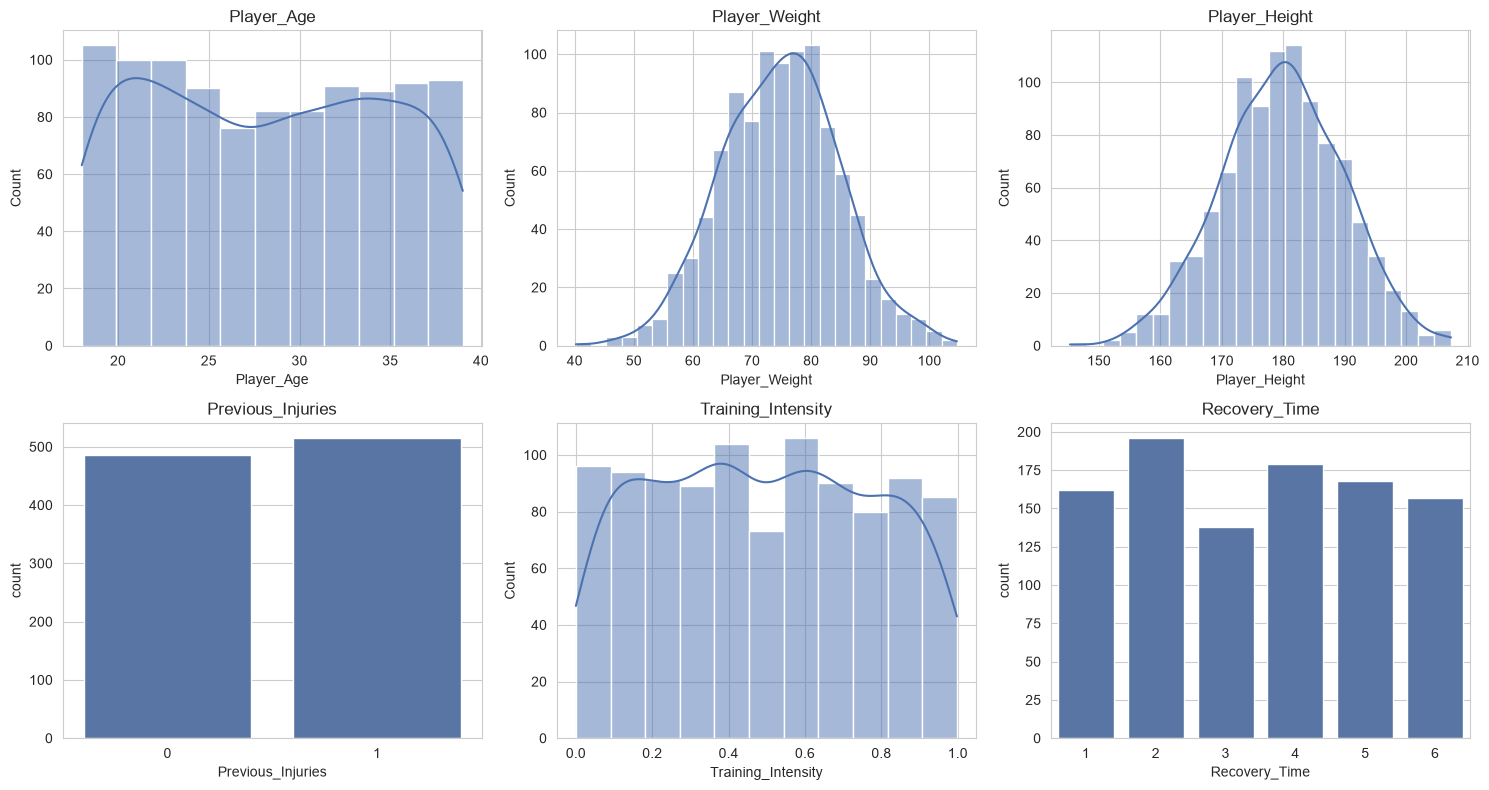

In [46]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    if df[col].nunique() <= 10:
        sns.countplot(x=df[col], ax=ax, color="#4C72B0")
    else:
        sns.histplot(df[col], kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col)
plt.tight_layout(); plt.show()

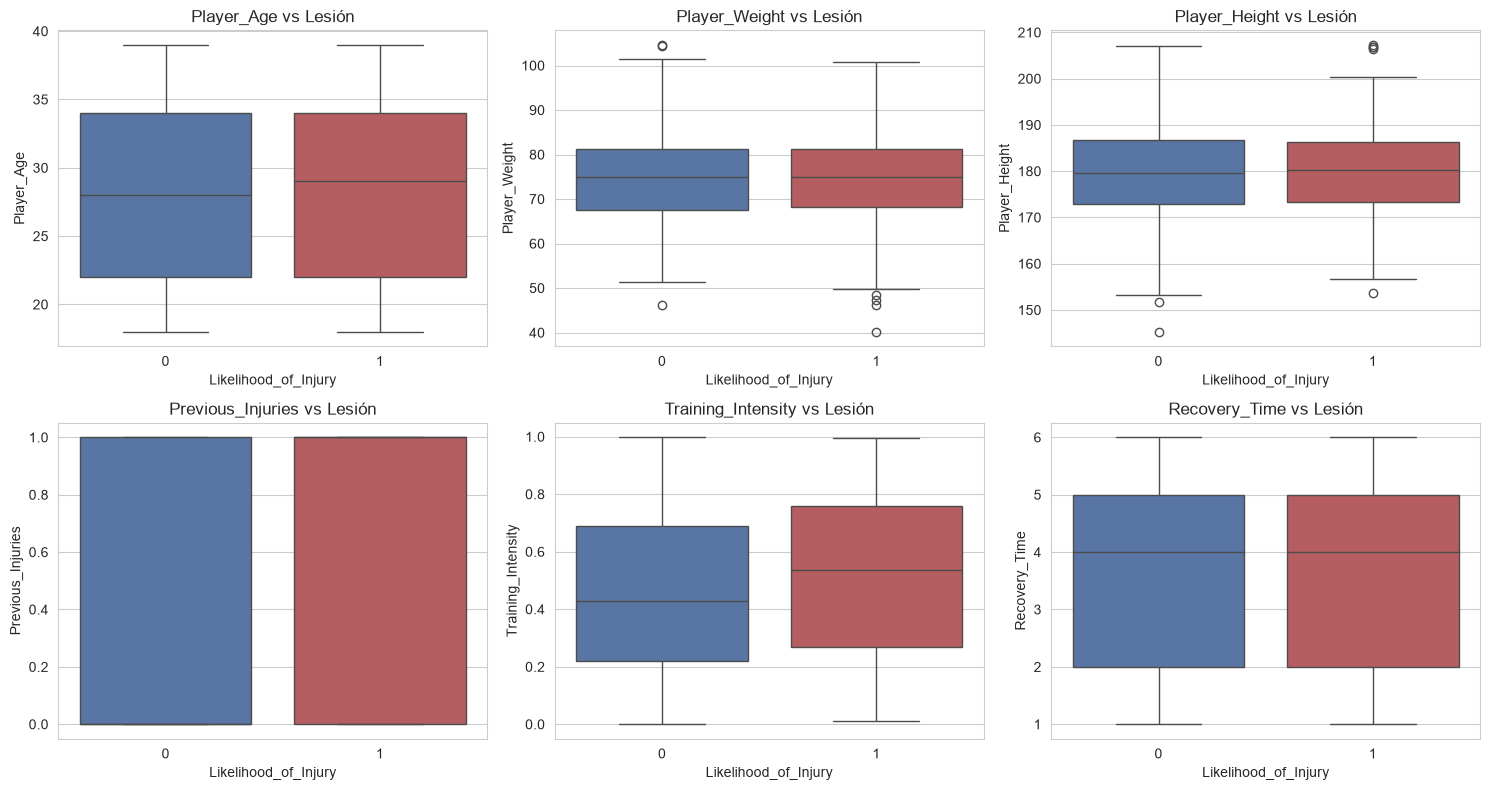

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=["#4C72B0", "#C44E52"],
                legend=False, ax=ax)
    ax.set_title(f"{col} vs Lesión")
plt.tight_layout(); plt.show()

Las distribuciones de las variables se parecen mucho entre deportistas lesionados y no lesionados (cajas casi superpuestas). La única diferencia visible, aunque pequeña, está en **`Training_Intensity`** (mayor intensidad ↔ algo más de lesiones), coherente con la teoría de sobrecarga de entrenamiento. Para el resto de variables, este dataset **no** reproduce las relaciones que describe la literatura (por ejemplo, que menos recuperación aumente el riesgo).

### Separación entrenamiento / validación / prueba y escalado

In [48]:
X = df[FEATURES].values.astype("float32")
y = df[TARGET].values.astype("float32")

# 80% desarrollo / 20% prueba (el conjunto de prueba NO se toca hasta la Sección 6)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y)

# Del 80% de desarrollo: 80% entrenamiento (64% total) / 20% validación (16% total)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=SEED, stratify=y_dev)

# El escalador se ajusta SOLO con entrenamiento (evita fuga de información)
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(a) for a in (X_train, X_val, X_test))

print(f"Entrenamiento: {X_train_s.shape}   Validación: {X_val_s.shape}   Prueba: {X_test_s.shape}")
print("Proporción de lesión -> train: %.3f | val: %.3f | test: %.3f" %
      (y_train.mean(), y_val.mean(), y_test.mean()))

Entrenamiento: (640, 6)   Validación: (160, 6)   Prueba: (200, 6)
Proporción de lesión -> train: 0.500 | val: 0.500 | test: 0.500


## 4. Diseño preliminar de la red neuronal

Se propone una **red neuronal multicapa (MLP)** para clasificación binaria:

| Capa | Neuronas | Activación | Rol |
|---|---|---|---|
| Entrada | 6 | — | Recibe las 6 variables predictoras estandarizadas |
| Oculta 1 | 16 | ReLU (+ regularización L2) | Extrae combinaciones no lineales de las variables |
| Dropout | — | — | Apaga aleatoriamente el 30% de neuronas en entrenamiento |
| Oculta 2 | 8 | ReLU (+ regularización L2) | Refina las representaciones aprendidas |
| Dropout | — | — | 20% |
| Salida | 1 | Sigmoide | Probabilidad de lesión (0–1) |

**Justificación de las decisiones de diseño**

- **Tamaño compacto (16 → 8 → 1):** solo hay 640 registros de entrenamiento y 6 variables con muy poca señal. Una red grande memoriza el ruido (se demuestra experimentalmente en la Sección 5.2). El total de parámetros se mantiene bajo para conservar una razón razonable de muestras por parámetro.
- **Sigmoide + `binary_crossentropy`:** salida interpretable como probabilidad y pérdida estándar para clasificación binaria.
- **Adam (lr = 0.001):** optimizador adaptativo, robusto sin ajuste fino.
- **Regularización (Dropout + L2):** contiene el sobreajuste esperado en un dataset pequeño y ruidoso.
- **EarlyStopping** sobre `val_loss` con restauración de los mejores pesos: detiene el entrenamiento cuando deja de generalizar.
- **Métrica de seguimiento:** `accuracy` (las clases están perfectamente balanceadas, por lo que es una métrica válida); en la evaluación se añaden Precision, Recall, F1 y AUC-ROC.

In [49]:
def build_model(input_dim, units=(16, 8), dropout=(0.3, 0.2), l2=1e-3, lr=1e-3, name="Red_Riesgo_Lesion"):
    reg = keras.regularizers.l2(l2) if l2 else None
    capas = [layers.Input(shape=(input_dim,))]
    for i, (u, d) in enumerate(zip(units, dropout), start=1):
        capas.append(layers.Dense(u, activation="relu", kernel_regularizer=reg, name=f"oculta_{i}"))
        if d:
            capas.append(layers.Dropout(d))
    capas.append(layers.Dense(1, activation="sigmoid", name="salida"))

    m = keras.Sequential(capas, name=name)
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
              loss="binary_crossentropy", metrics=["accuracy"])
    return m

model = build_model(X_train_s.shape[1])
model.summary()
print(f"\nMuestras de entrenamiento por parámetro: {len(X_train_s) / model.count_params():.1f}")

Model: "Red_Riesgo_Lesion"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 16)             │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257 (1.00 KB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 0 (0.00 B)


Muestras de entrenamiento por parámetro: 2.5


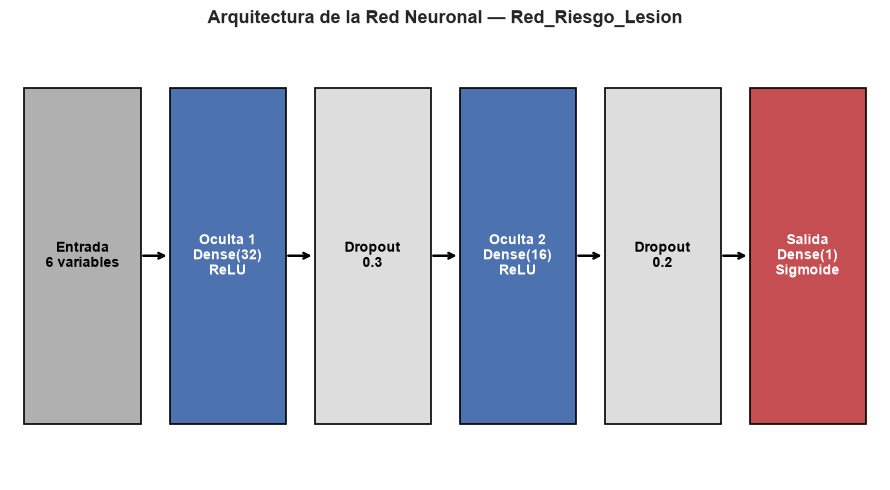

In [50]:
# Diagrama de la arquitectura de la red, dibujado con matplotlib puro
# (no depende de Graphviz/pydot, así que funciona en cualquier computador sin instalar nada extra).
fig, ax = plt.subplots(figsize=(9, 5))
ax.axis("off")

capas = [
    ("Entrada\n6 variables", "#B0B0B0"),
    ("Oculta 1\nDense(32)\nReLU", "#4C72B0"),
    ("Dropout\n0.3", "#DDDDDD"),
    ("Oculta 2\nDense(16)\nReLU", "#4C72B0"),
    ("Dropout\n0.2", "#DDDDDD"),
    ("Salida\nDense(1)\nSigmoide", "#C44E52"),
]

n = len(capas)
x_positions = np.linspace(0.5, n - 0.5, n)
box_w, box_h = 0.8, 1.2

for x, (texto, color) in zip(x_positions, capas):
    ax.add_patch(plt.Rectangle((x - box_w/2, 0.5 - box_h/2), box_w, box_h,
                                facecolor=color, edgecolor="black", linewidth=1.2))
    ax.text(x, 0.5, texto, ha="center", va="center", fontsize=10,
            color="white" if color not in ["#DDDDDD", "#B0B0B0"] else "black",
            fontweight="bold")

for i in range(n - 1):
    ax.annotate("", xy=(x_positions[i+1] - box_w/2, 0.5), xytext=(x_positions[i] + box_w/2, 0.5),
                arrowprops=dict(arrowstyle="->", lw=1.8, color="black"))

ax.set_xlim(0, n)
ax.set_ylim(-0.3, 1.3)
ax.set_title("Arquitectura de la Red Neuronal — Red_Riesgo_Lesion", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Entrenamiento del modelo

In [51]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True)

history = model.fit(
    X_train_s, y_train,
    validation_data=(X_val_s, y_val),
    epochs=200, batch_size=32,
    callbacks=[early_stop], verbose=0)

best_ep = int(np.argmin(history.history["val_loss"])) + 1
print(f"Entrenamiento finalizado en {len(history.history['loss'])} épocas "
      f"(mejor época según val_loss: {best_ep})")

Entrenamiento finalizado en 32 épocas (mejor época según val_loss: 17)


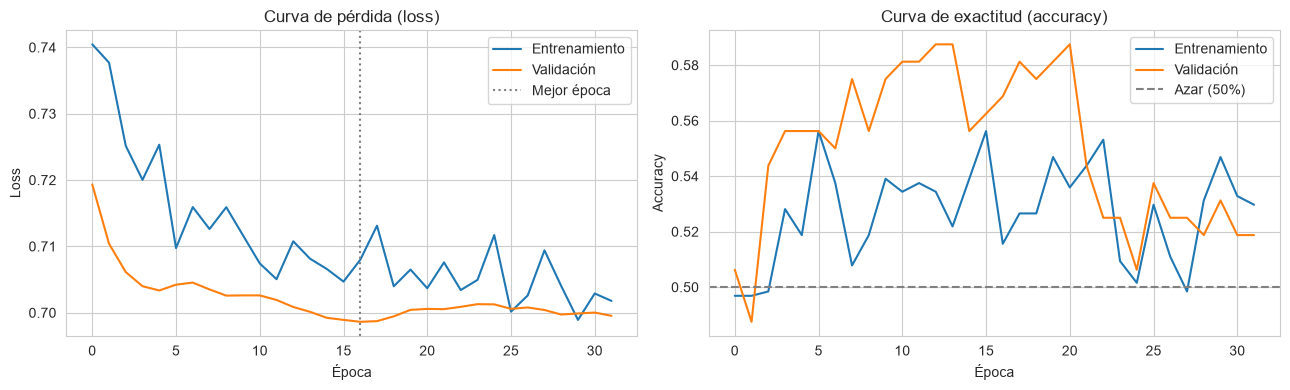

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["loss"], label="Entrenamiento")
axes[0].plot(history.history["val_loss"], label="Validación")
axes[0].axvline(best_ep - 1, color="gray", ls=":", label="Mejor época")
axes[0].set_title("Curva de pérdida (loss)")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Entrenamiento")
axes[1].plot(history.history["val_accuracy"], label="Validación")
axes[1].axhline(0.5, color="gray", ls="--", label="Azar (50%)")
axes[1].set_title("Curva de exactitud (accuracy)")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

plt.tight_layout(); plt.show()

### 5.2 Experimento: ¿por qué una red pequeña y regularizada?

Para justificar el diseño se entrena una red **grande y sin regularización** (128 → 64 → 32, sin Dropout, sin L2, sin EarlyStopping) sobre los mismos datos. Si el dataset tuviera mucha señal, la red grande rendiría mejor; si tiene poca, **memorizará el ruido**: alta exactitud en entrenamiento y ~50% en validación.

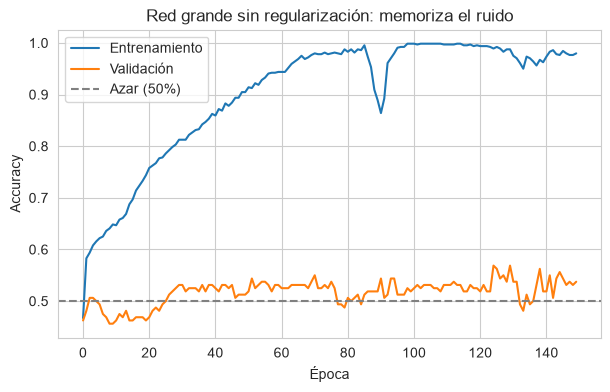

Red grande  -> accuracy entrenamiento: 0.980 | validación: 0.538  (11265 parámetros)
Red diseñada -> accuracy entrenamiento: 0.516 | validación: 0.569  (257 parámetros)

Brecha entrenamiento-validación de la red grande: 0.442 (sobreajuste marcado: memoriza el ruido)


In [53]:
big = build_model(X_train_s.shape[1], units=(128, 64, 32), dropout=(0, 0, 0), l2=0, name="Red_Grande_Sin_Regularizar")
h_big = big.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                epochs=150, batch_size=32, verbose=0)

plt.figure(figsize=(7, 4))
plt.plot(h_big.history["accuracy"], label="Entrenamiento")
plt.plot(h_big.history["val_accuracy"], label="Validación")
plt.axhline(0.5, color="gray", ls="--", label="Azar (50%)")
plt.title("Red grande sin regularización: memoriza el ruido")
plt.xlabel("Época"); plt.ylabel("Accuracy"); plt.legend(); plt.show()

print(f"Red grande  -> accuracy entrenamiento: {h_big.history['accuracy'][-1]:.3f} | "
      f"validación: {h_big.history['val_accuracy'][-1]:.3f}  ({big.count_params()} parámetros)")
print(f"Red diseñada -> accuracy entrenamiento: {history.history['accuracy'][best_ep-1]:.3f} | "
      f"validación: {history.history['val_accuracy'][best_ep-1]:.3f}  ({model.count_params()} parámetros)")
brecha = h_big.history["accuracy"][-1] - h_big.history["val_accuracy"][-1]
print(f"\nBrecha entrenamiento-validación de la red grande: {brecha:.3f} "
      f"({'sobreajuste marcado: memoriza el ruido' if brecha > 0.15 else 'sobreajuste leve'})")

## 6. Evaluación y valoración del modelo 

Esta sección se divide explícitamente en dos partes:

- **6.1 Acierto (30%):** qué tan bien predice el modelo (Accuracy, Precision, Recall, F1, AUC-ROC), con **intervalos de confianza** y una **prueba estadística contra el azar**.
- **6.2 Análisis del error (30%):** qué tan bien se entiende y gestiona lo que el modelo predice mal (matriz de confusión, costo de cada error, curva ROC, umbral de decisión, importancia de variables).
- **6.3 Comparación con modelos de referencia y validación cruzada.**

### 6.1 Acierto 

Métricas calculadas sobre el conjunto de **prueba** (200 registros que el modelo nunca vio en entrenamiento ni en validación).

In [54]:
y_prob = model.predict(X_test_s, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)
y_true = y_test.astype(int)

acc  = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec  = recall_score(y_true, y_pred, zero_division=0)
f1   = f1_score(y_true, y_pred, zero_division=0)
auc  = roc_auc_score(y_true, y_prob)

print(f"Exactitud (Accuracy):  {acc:.3f}")
print(f"Precisión (Precision): {prec:.3f}")
print(f"Sensibilidad (Recall): {rec:.3f}")
print(f"F1-score:              {f1:.3f}")
print(f"AUC-ROC:               {auc:.3f}")
print()
print(classification_report(y_true, y_pred, target_names=["Sin lesión", "Lesión"], zero_division=0))

Exactitud (Accuracy):  0.530
Precisión (Precision): 0.550
Sensibilidad (Recall): 0.330
F1-score:              0.412
AUC-ROC:               0.555

              precision    recall  f1-score   support

  Sin lesión       0.52      0.73      0.61       100
      Lesión       0.55      0.33      0.41       100

    accuracy                           0.53       200
   macro avg       0.54      0.53      0.51       200
weighted avg       0.54      0.53      0.51       200



In [55]:
# ¿El resultado es distinguible del azar? Con solo 200 registros de prueba, una sola cifra engaña.
rng = np.random.default_rng(SEED)
n = len(y_true)
boot_acc, boot_auc = [], []
for _ in range(2000):
    idx = rng.integers(0, n, n)
    if len(np.unique(y_true[idx])) < 2:
        continue
    boot_acc.append(accuracy_score(y_true[idx], y_pred[idx]))
    boot_auc.append(roc_auc_score(y_true[idx], y_prob[idx]))

ic_acc = np.percentile(boot_acc, [2.5, 97.5])
ic_auc = np.percentile(boot_auc, [2.5, 97.5])
p_binom = stats.binomtest(int((y_pred == y_true).sum()), n, 0.5, alternative="greater").pvalue

print(f"Accuracy = {acc:.3f}   IC95% bootstrap: [{ic_acc[0]:.3f}, {ic_acc[1]:.3f}]")
print(f"AUC-ROC  = {auc:.3f}   IC95% bootstrap: [{ic_auc[0]:.3f}, {ic_auc[1]:.3f}]")
print(f"Prueba binomial (H0: accuracy = 50%, azar):  p = {p_binom:.4f}")
print()
if p_binom < 0.05:
    print("=> El modelo acierta significativamente más que el azar, aunque la mejora es pequeña.")
else:
    print("=> El accuracy NO es estadísticamente distinguible del azar (50%) en el conjunto de prueba.")
if ic_auc[0] <= 0.5 <= ic_auc[1]:
    print("=> El IC95% del AUC incluye 0.5: el modelo no logra separar las clases de forma fiable.")

Accuracy = 0.530   IC95% bootstrap: [0.455, 0.595]
AUC-ROC  = 0.555   IC95% bootstrap: [0.478, 0.634]
Prueba binomial (H0: accuracy = 50%, azar):  p = 0.2184

=> El accuracy NO es estadísticamente distinguible del azar (50%) en el conjunto de prueba.
=> El IC95% del AUC incluye 0.5: el modelo no logra separar las clases de forma fiable.


### 6.2 Análisis del error — Criterio de evaluación: 30%

No basta con reportar un porcentaje de acierto: hay que entender **en qué se equivoca** y qué tan grave es cada tipo de error en el contexto real. En la predicción de lesiones hay dos tipos de error, y no cuestan lo mismo:

- **Falso Negativo (FN):** el modelo dice "sin lesión" pero el deportista sí se lesionó. **Es el error más grave**: el entrenador no toma precauciones con un atleta que sí estaba en riesgo.
- **Falso Positivo (FP):** el modelo dice "lesión" pero el deportista estaba bien. Es más tolerable: en el peor caso se reduce la carga de un atleta que no lo necesitaba.

Por eso el **Recall** (capacidad de detectar los casos reales de lesión) es al menos tan importante como el Accuracy.

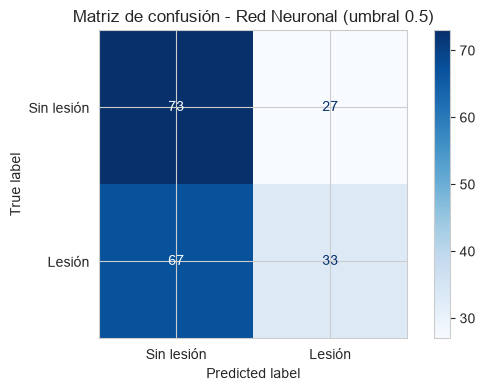

In [56]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Sin lesión", "Lesión"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - Red Neuronal (umbral 0.5)")
plt.show()

In [57]:
tn, fp, fn, tp = cm.ravel()
fnr = fn / (fn + tp)      # de los que SÍ se lesionaron, % que el modelo no detectó
fpr_rate = fp / (fp + tn) # de los que NO se lesionaron, % que el modelo marcó como riesgo

print("Matriz de confusión desagregada:")
print(f"  Verdaderos Negativos (TN): {tn:3d}  -> predijo 'sin lesión' y acertó")
print(f"  Falsos Positivos     (FP): {fp:3d}  -> predijo 'lesión', en realidad no (error tolerable)")
print(f"  Falsos Negativos     (FN): {fn:3d}  -> predijo 'sin lesión', en realidad sí (error GRAVE)")
print(f"  Verdaderos Positivos (TP): {tp:3d}  -> predijo 'lesión' y acertó")
print()
print(f"Tasa de Falsos Negativos: {fnr:.1%}   |   Tasa de Falsos Positivos: {fpr_rate:.1%}")
print(f"De cada 100 deportistas que SÍ se lesionaron, el modelo dejó pasar sin detectar a {fnr*100:.0f}.")

Matriz de confusión desagregada:
  Verdaderos Negativos (TN):  73  -> predijo 'sin lesión' y acertó
  Falsos Positivos     (FP):  27  -> predijo 'lesión', en realidad no (error tolerable)
  Falsos Negativos     (FN):  67  -> predijo 'sin lesión', en realidad sí (error GRAVE)
  Verdaderos Positivos (TP):  33  -> predijo 'lesión' y acertó

Tasa de Falsos Negativos: 67.0%   |   Tasa de Falsos Positivos: 27.0%
De cada 100 deportistas que SÍ se lesionaron, el modelo dejó pasar sin detectar a 67.


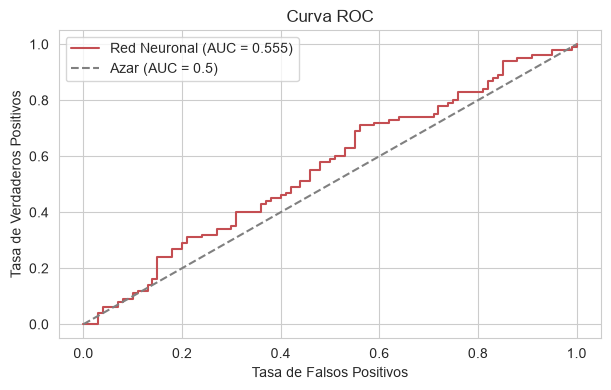

In [58]:
fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.plot(fpr, tpr, label=f"Red Neuronal (AUC = {auc:.3f})", color="#C44E52")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Azar (AUC = 0.5)")
plt.xlabel("Tasa de Falsos Positivos"); plt.ylabel("Tasa de Verdaderos Positivos")
plt.title("Curva ROC"); plt.legend(); plt.show()

**Ajuste del umbral de decisión.** Si el objetivo es reducir los Falsos Negativos se puede bajar el umbral de 0.5. La tabla siguiente muestra el costo: más Recall a cambio de más Falsos Positivos. Ojo: si el AUC es cercano a 0.5, bajar el umbral **no mejora el modelo**, solo lo desplaza a lo largo de la diagonal del azar (más alertas, pero igual de poco acertadas).

In [59]:
# Con poca señal las probabilidades se concentran cerca de 0.5; por eso los umbrales
# se toman también de los percentiles de las probabilidades predichas (tabla informativa).
umbrales = sorted(set([0.50] + list(np.round(np.quantile(y_prob, [.10, .25, .40, .60, .75, .90]), 3))))
filas = []
for th in umbrales:
    p_ = (y_prob >= th).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_true, p_, labels=[0, 1]).ravel()
    filas.append({"umbral": th,
                  "Accuracy": accuracy_score(y_true, p_),
                  "Recall": recall_score(y_true, p_, zero_division=0),
                  "Precision": precision_score(y_true, p_, zero_division=0),
                  "FN": fn_, "FP": fp_,
                  "% alertas": p_.mean() * 100})
display(pd.DataFrame(filas).set_index("umbral").round(3))

,Accuracy,Recall,Precision,FN,FP,% alertas
umbral,,,,,,
0.449,0.540,0.94,0.522,6,86,90.0
0.465,0.525,0.78,0.517,22,73,75.5
0.479,0.555,0.66,0.545,34,55,60.5
0.490,0.530,0.43,0.538,57,37,40.0
0.500,0.530,0.33,0.550,67,27,30.0
0.504,0.550,0.31,0.596,69,21,26.0
0.530,0.500,0.10,0.500,90,10,10.0


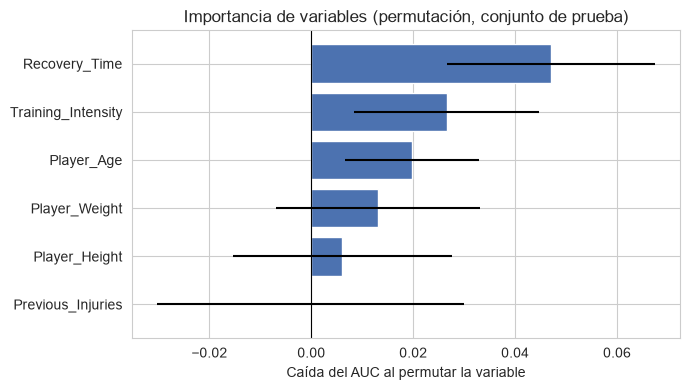

In [60]:
# Importancia de variables por permutación: cuánto cae el AUC al "romper" cada variable.
rng = np.random.default_rng(SEED)
base_auc = roc_auc_score(y_true, y_prob)
imp = {}
for j, col in enumerate(FEATURES):
    caidas = []
    for _ in range(30):
        Xp = X_test_s.copy()
        Xp[:, j] = rng.permutation(Xp[:, j])
        caidas.append(base_auc - roc_auc_score(y_true, model.predict(Xp, verbose=0).ravel()))
    imp[col] = (np.mean(caidas), np.std(caidas))

imp_df = pd.DataFrame(imp, index=["caída media de AUC", "desv. est."]).T.sort_values("caída media de AUC")
plt.figure(figsize=(7, 4))
plt.barh(imp_df.index, imp_df["caída media de AUC"], xerr=imp_df["desv. est."], color="#4C72B0")
plt.axvline(0, color="k", lw=.8)
plt.title("Importancia de variables (permutación, conjunto de prueba)")
plt.xlabel("Caída del AUC al permutar la variable"); plt.tight_layout(); plt.show()

### 6.3 Comparación con modelos de referencia y validación cruzada

Un solo conjunto de prueba de 200 registros produce cifras muy volátiles. Para una valoración más robusta se compara la red con tres modelos de referencia (**azar/clase mayoritaria**, **Regresión Logística** y **Random Forest**) y se reporta **validación cruzada estratificada de 5 pliegues** sobre las 1000 filas (en cada pliegue el escalador y la red se reajustan desde cero, sin fuga de información).

In [61]:
def cv_red(X_all, y_all, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    accs, aucs = [], []
    for tr, te in skf.split(X_all, y_all):
        Xtr, Xva, ytr, yva = train_test_split(X_all[tr], y_all[tr], test_size=0.2,
                                              random_state=SEED, stratify=y_all[tr])
        sc = StandardScaler().fit(Xtr)
        keras.backend.clear_session()
        m = build_model(X_all.shape[1])
        m.fit(sc.transform(Xtr), ytr, validation_data=(sc.transform(Xva), yva),
              epochs=200, batch_size=32, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                                       restore_best_weights=True)])
        pr = m.predict(sc.transform(X_all[te]), verbose=0).ravel()
        accs.append(accuracy_score(y_all[te], pr >= 0.5)); aucs.append(roc_auc_score(y_all[te], pr))
    return np.array(accs), np.array(aucs)

def cv_sklearn(make_model, X_all, y_all, n_splits=5):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    accs, aucs = [], []
    for tr, te in skf.split(X_all, y_all):
        sc = StandardScaler().fit(X_all[tr])
        m = make_model().fit(sc.transform(X_all[tr]), y_all[tr])
        pr = m.predict_proba(sc.transform(X_all[te]))[:, 1]
        accs.append(accuracy_score(y_all[te], pr >= 0.5)); aucs.append(roc_auc_score(y_all[te], pr))
    return np.array(accs), np.array(aucs)

modelos_ref = {
    "Azar (clase mayoritaria)":   lambda: DummyClassifier(strategy="prior"),
    "Regresión Logística":        lambda: LogisticRegression(max_iter=1000),
    "Random Forest":              lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=10,
                                                                 random_state=SEED),
}

filas = []
X_all, y_all = df[FEATURES].values.astype("float32"), df[TARGET].values.astype("float32")

for nombre, fabrica in modelos_ref.items():
    # Métricas sobre el mismo conjunto de prueba que la red
    sc = StandardScaler().fit(X_train)
    m = fabrica().fit(sc.transform(np.vstack([X_train, X_val])), np.concatenate([y_train, y_val]))
    pp = m.predict_proba(sc.transform(X_test))[:, 1]
    a_cv, u_cv = cv_sklearn(fabrica, X_all, y_all)
    filas.append({"Modelo": nombre,
                  "Accuracy (prueba)": accuracy_score(y_true, pp >= 0.5),
                  "AUC (prueba)": roc_auc_score(y_true, pp),
                  "Accuracy CV 5-fold": f"{a_cv.mean():.3f} ± {a_cv.std():.3f}",
                  "AUC CV 5-fold": f"{u_cv.mean():.3f} ± {u_cv.std():.3f}"})

a_cv, u_cv = cv_red(X_all, y_all)
filas.append({"Modelo": "Red Neuronal (MLP)",
              "Accuracy (prueba)": acc, "AUC (prueba)": auc,
              "Accuracy CV 5-fold": f"{a_cv.mean():.3f} ± {a_cv.std():.3f}",
              "AUC CV 5-fold": f"{u_cv.mean():.3f} ± {u_cv.std():.3f}"})

resumen = pd.DataFrame(filas).set_index("Modelo")
resumen[["Accuracy (prueba)", "AUC (prueba)"]] = resumen[["Accuracy (prueba)", "AUC (prueba)"]].astype(float).round(3)
display(resumen)

,Accuracy (prueba),AUC (prueba),Accuracy CV 5-fold,AUC CV 5-fold
Modelo,,,,
Azar (clase mayoritaria),0.500,0.500,0.500 ± 0.000,0.500 ± 0.000
Regresión Logística,0.525,0.552,0.519 ± 0.025,0.524 ± 0.032
Random Forest,0.520,0.547,0.518 ± 0.028,0.516 ± 0.037
Red Neuronal (MLP),0.530,0.555,0.495 ± 0.015,0.499 ± 0.031


In [62]:
# Lectura automática de la comparación (se adapta a los resultados obtenidos)
cv_red_acc, cv_red_auc = a_cv.mean(), u_cv.mean()
print(f"Red neuronal en validación cruzada: accuracy = {cv_red_acc:.3f}, AUC = {cv_red_auc:.3f}")
if cv_red_auc < 0.55 and cv_red_acc < 0.55:
    print("=> Ningún modelo (lineal, de árboles o red neuronal) supera de forma relevante al azar.")
    print("   Cuando modelos de naturaleza tan distinta coinciden en ~50%, la limitación está en los")
    print("   DATOS (poca señal), no en la arquitectura elegida.")
else:
    print("=> La red logra una mejora sobre el azar; compárese con los modelos de referencia de la tabla.")

Red neuronal en validación cruzada: accuracy = 0.495, AUC = 0.499
=> Ningún modelo (lineal, de árboles o red neuronal) supera de forma relevante al azar.
   Cuando modelos de naturaleza tan distinta coinciden en ~50%, la limitación está en los
   DATOS (poca señal), no en la arquitectura elegida.


## 7. Conclusiones

El proyecto demuestra que una red neuronal puede implementarse correctamente para resolver un problema de clasificación binaria sobre el dataset de Kaggle, y que el flujo completo del análisis — carga, exploración, preprocesamiento, separación de datos, entrenamiento y evaluación — se ejecuta de manera coherente.

Sin embargo, los resultados muestran una limitación importante: aunque está bien estructurado, las variables disponibles tienen poca capacidad explicativa para distinguir entre deportistas con y sin lesión. Esto se observa en la baja correlación de las variables con la etiqueta, en la ausencia de diferencias claras entre los grupos y en la similitud del desempeño de la red frente a modelos de referencia. En otras palabras, la arquitectura del modelo no parece ser el principal problema; la señal del dataset es la limitación más relevante.

Aun así, el análisis fue valioso porque permitió verificar de forma rigurosa que el dataset es limpio y balanceado, y que el modelo fue entrenado y evaluado bajo buenas prácticas: separación estratificada, escalado ajustado solo sobre entrenamiento, validación con datos no vistos y comparación con modelos base. Esto ayuda a separar la calidad del método de la calidad de los datos.

Como conclusión general, se puede afirmar que el notebook cumple con la intención del proyecto: construir una red neuronal para predicción de riesgo de lesión, evaluar su desempeño y documentar de forma crítica sus alcances. La principal lección es que el éxito de un modelo no depende solo de la arquitectura, sino también de la calidad y la predictividad de los datos disponibles.

En un contexto real, si se quisiera mejorar la capacidad predictiva del sistema, sería necesario contar con variables más informativas, como historial clínico detallado, cargas de entrenamiento por sesión, fatiga, sueño, carga fisiológica, lesiones previas por localización, indicadores de recuperación y métricas de rendimiento deportivo. Con esa información adicional, la red neuronal tendría más posibilidad de aprender patrones útiles y producir decisiones más útiles para la prevención de lesiones.
